# Running with AI: pełny kod

Ta wersja zawiera kompletny kod prowadzącego do przejścia przez cały pipeline krok po kroku.

## Cele warsztatów

Po przejściu przez notebook uczestnicy:
- zobaczą, jak połączyć dane ze Stravy i Garmina,
- przejdą przez typowe etapy czyszczenia i walidacji danych sportowych,
- zbudują prosty model predykcyjny,
- poznają ideę modelu sekwencyjnego GRU dla danych treningowych.

## Plan warsztatów

1. Wczytanie i zrozumienie danych.
2. Ujednolicenie formatów ze Stravy i Garmina.
3. Czyszczenie danych i obsługa braków.
4. Wykrywanie biegów startowych.
5. Zbudowanie cech do modelu.
6. Trening modelu bazowego.
7. Model sekwencyjny GRU jako główny model warsztatów.

In [15]:
from pathlib import Path
from dateutil import parser

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)

try:
    import tensorflow as tf
    from tensorflow.keras.models import Model
    from tensorflow.keras.layers import Input, GRU, Dense, Dropout, concatenate, BatchNormalization, Masking, Bidirectional
    from tensorflow.keras.optimizers import Adam
    from tensorflow.keras.losses import Huber
    from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    tf.random.set_seed(SEED)
    TF_AVAILABLE = True
except ImportError:
    TF_AVAILABLE = False


def find_repo_root() -> Path:
    """Znajdź katalog repo niezależnie od miejsca uruchomienia notebooka."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Nie udało się znaleźć katalogu repozytorium z folderem data/.")


PROJECT_ROOT = find_repo_root()
STRAVA_DIR = PROJECT_ROOT / "data" / "strava_activities"
GARMIN_DIR = PROJECT_ROOT / "data" / "garmin_activities"

print(f"Repozytorium: {PROJECT_ROOT}")
print(f"TensorFlow dostępny: {TF_AVAILABLE}")


Repozytorium: /content
TensorFlow dostępny: True


## 1. Wczytanie danych ze Stravy

W oryginalnym projekcie dane pochodzą z wielu eksportów CSV. Tutaj zachowujemy tylko kolumny, które będą przydatne na warsztatach.

In [16]:
def parse_mixed_date(value):
    try:
        return parser.parse(str(value), dayfirst=False)
    except Exception:
        return pd.NaT


STRAVA_COLUMNS = [
    "Activity ID", "Activity Date", "Activity Type",
    "Elapsed Time", "Moving Time", "Distance",
    "Max Heart Rate", "Average Heart Rate",
    "Max Speed", "Average Speed",
    "Elevation Gain", "Elevation Loss",
    "Average Temperature",
]


def load_strava_exports(directory: Path) -> pd.DataFrame:
    dfs = []
    files = sorted(directory.glob("*.csv"))

    for i, path in enumerate(files, start=1):
        df_temp = pd.read_csv(path, usecols=lambda c: c in STRAVA_COLUMNS, low_memory=False)
        df_temp = df_temp.replace(["--", "", "None"], np.nan)
        df_temp["athlete"] = f"strava_{i:02d}"
        df_temp["source"] = "strava"
        df_temp["Activity Date"] = df_temp["Activity Date"].apply(parse_mixed_date)

        numeric_cols = [
            "Elapsed Time", "Moving Time", "Distance", "Max Heart Rate", "Average Heart Rate",
            "Max Speed", "Average Speed", "Elevation Gain", "Elevation Loss", "Average Temperature"
        ]
        for col in numeric_cols:
            if col in df_temp.columns:
                df_temp[col] = pd.to_numeric(df_temp[col], errors="coerce")

        dfs.append(df_temp)

    if not dfs:
        raise FileNotFoundError(f"Nie znaleziono plików CSV w {directory}")

    return pd.concat(dfs, ignore_index=True)


strava_df = load_strava_exports(STRAVA_DIR)
print(strava_df.shape)
strava_df.head()

(17499, 15)


,Activity ID,Activity Date,Activity Type,Elapsed Time,Distance,Max Heart Rate,Moving Time,Max Speed,Average Speed,Elevation Gain,Elevation Loss,Average Heart Rate,Average Temperature,athlete,source
0,7960569397,2022-10-14 08:28:54,Run,227,0.55,NaN,153.0,5.930,3.628,0.0,-1.6,NaN,NaN,strava_01,strava
1,7960615374,2022-10-14 09:09:26,Run,261,0.87,NaN,255.0,5.532,3.414,2.9,4.0,NaN,NaN,strava_01,strava
2,7967668722,2022-10-15 16:32:24,Run,300,0.77,NaN,229.0,12.265,3.401,0.0,1.3,NaN,NaN,strava_01,strava
3,7967926482,2022-10-15 16:41:09,Run,2231,6.97,NaN,2057.0,7.296,3.390,6.2,6.3,NaN,NaN,strava_01,strava
4,7968002040,2022-10-15 17:40:51,Run,343,0.74,NaN,337.0,3.422,2.194,0.0,-1.2,NaN,NaN,strava_01,strava


## 2. Wczytanie danych z Garmina

Dane z Garmina mają inny schemat:
- kolumny po polsku,
- liczby z przecinkiem,
- prędkość lub tempo zapisane jako tekst,
- czas zapisany jako `HH:MM:SS`.

To bardzo dobry przykład realnego problemu integracji danych.

In [17]:
GARMIN_COLUMN_MAP = {
    "Typ aktywności": "Activity Type",
    "Data": "Activity Date",
    "Dystans": "Distance",
    "Czas": "Elapsed Time",
    "Czas ruchu": "Moving Time",
    "Maksymalne tętno": "Max Heart Rate",
    "Średnie tętno": "Average Heart Rate",
    "Całkowity wznios": "Elevation Gain",
    "Całkowity spadek": "Elevation Loss",
    "Maksymalna prędkość": "Max Speed",
    "Średnia prędkość": "Average Speed",
    "Średnie tempo": "Average Speed",
    "Najlepsze tempo": "Max Speed",
    "Maksymalna temperatura": "Max Temperature",
    "Minimalna temperatura": "Min Temperature",
}

GARMIN_ACTIVITY_MAP = {
    "Bieganie": "Run",
    "Bieg na bieżni": "Run",
    "Virtual Run": "Run",
    "Kolarstwo": "Ride",
    "Kolarstwo szosowe": "Ride",
    "Jazda na rowerze treningowym": "Ride",
    "Jazda po drodze szutrowej/nieutwardzonej": "Ride",
    "Virtual Ride": "Ride",
    "Pływanie na basenie": "Swim",
    "Pływanie open water": "Swim",
    "Trening siłowy": "Weight Training",
    "Run": "Run",
    "Ride": "Ride",
    "Swim": "Swim",
    "Weight Training": "Weight Training",
}


def collapse_duplicate_columns(df: pd.DataFrame) -> pd.DataFrame:
    if not df.columns.duplicated().any():
        return df

    collapsed = {}
    for col in dict.fromkeys(df.columns):
        same_name = df.loc[:, df.columns == col]
        if same_name.shape[1] == 1:
            collapsed[col] = same_name.iloc[:, 0]
        else:
            collapsed[col] = same_name.bfill(axis=1).iloc[:, 0]
    return pd.DataFrame(collapsed)


def fix_temperature(df_temp: pd.DataFrame) -> pd.DataFrame:
    if {"Max Temperature", "Min Temperature"}.issubset(df_temp.columns):
        for col in ["Max Temperature", "Min Temperature"]:
            df_temp[col] = (
                df_temp[col]
                .astype(str)
                .str.replace(",", ".", regex=False)
                .replace(["", "nan", "None", "--"], np.nan)
            )
            df_temp[col] = pd.to_numeric(df_temp[col], errors="coerce")
        df_temp["Average Temperature"] = df_temp[["Max Temperature", "Min Temperature"]].mean(axis=1)
        df_temp = df_temp.drop(columns=["Max Temperature", "Min Temperature"], errors="ignore")
    return df_temp


def parse_garmin_speed(value, activity_type):
    if pd.isna(value) or value in ["--", "", None]:
        return np.nan

    value = str(value).replace(",", ".")

    try:
        if activity_type == "Ride":
            kmh = float(value)
        elif activity_type == "Run":
            mins, secs = map(float, value.split(":")) if ":" in value else (float(value), 0.0)
            pace_min_per_km = mins + secs / 60
            kmh = 60 / pace_min_per_km
        elif activity_type == "Swim":
            mins, secs = map(float, value.split(":")) if ":" in value else (float(value), 0.0)
            pace_min_per_100m = mins + secs / 60
            kmh = 60 / pace_min_per_100m * 10
        else:
            return np.nan
        return kmh * 1000 / 3600
    except Exception:
        return np.nan


def load_garmin_exports(directory: Path) -> pd.DataFrame:
    dfs = []
    files = sorted(directory.glob("*.csv"))

    for i, path in enumerate(files, start=1):
        df_temp = pd.read_csv(path)
        cols_to_keep = [c for c in df_temp.columns if c in GARMIN_COLUMN_MAP]
        df_temp = df_temp[cols_to_keep].rename(columns=GARMIN_COLUMN_MAP)
        df_temp = collapse_duplicate_columns(df_temp)
        df_temp = fix_temperature(df_temp)
        df_temp = df_temp.replace(["--", "", "None"], np.nan)

        df_temp["Activity Type"] = df_temp["Activity Type"].map(GARMIN_ACTIVITY_MAP).fillna("Workout")
        df_temp["Activity Date"] = pd.to_datetime(df_temp["Activity Date"], errors="coerce")

        for col in ["Elapsed Time", "Moving Time"]:
            if col in df_temp.columns:
                df_temp[col] = pd.to_timedelta(df_temp[col], errors="coerce").dt.total_seconds()

        numeric_cols = [
            "Distance", "Max Heart Rate", "Average Heart Rate",
            "Elevation Gain", "Elevation Loss", "Average Temperature"
        ]
        for col in numeric_cols:
            if col in df_temp.columns:
                df_temp[col] = (
                    df_temp[col]
                    .astype(str)
                    .str.replace(",", ".", regex=False)
                    .replace(["", "nan", "None", "--"], np.nan)
                )
                df_temp[col] = pd.to_numeric(df_temp[col], errors="coerce")

        for col in ["Average Speed", "Max Speed"]:
            if col in df_temp.columns:
                df_temp[col] = df_temp.apply(lambda row: parse_garmin_speed(row[col], row["Activity Type"]), axis=1)

        df_temp["athlete"] = f"garmin_{i:02d}"
        df_temp["source"] = "garmin"
        dfs.append(df_temp)

    if not dfs:
        raise FileNotFoundError(f"Nie znaleziono plików CSV w {directory}")

    return pd.concat(dfs, ignore_index=True)


garmin_df = load_garmin_exports(GARMIN_DIR)
print(garmin_df.shape)
garmin_df.head()

(720, 14)


,Activity Type,Activity Date,Distance,Elapsed Time,Average Heart Rate,Max Heart Rate,Average Speed,Max Speed,Elevation Gain,Elevation Loss,Moving Time,Average Temperature,athlete,source
0,Run,2025-09-19 21:33:31,6.44,2290.0,152.0,177.0,2.808989,3.508772,9.0,10.0,2277.0,22.5,garmin_01,garmin
1,Ride,2025-09-18 17:13:37,21.12,4209.0,124.0,150.0,5.027778,8.527778,81.0,83.0,4083.0,23.5,garmin_01,garmin
2,Ride,2025-09-15 17:42:33,21.32,4060.0,129.0,176.0,5.250000,8.166667,68.0,68.0,4004.0,24.0,garmin_01,garmin
3,Run,2025-09-13 08:40:54,10.10,3964.0,150.0,166.0,2.551020,3.267974,48.0,25.0,3949.0,23.5,garmin_01,garmin
4,Ride,2025-09-12 17:21:37,21.50,3972.0,132.0,168.0,5.416667,8.055556,75.0,80.0,3890.0,24.5,garmin_01,garmin


## 3. Szybki rzut oka na dane

Na tym etapie warto omówić:
- jakie typy aktywności mamy w danych,
- gdzie są braki,
- czy jednostki mają sens,
- które kolumny mogą być przydatne do modelowania.

In [18]:
raw_df = pd.concat([strava_df, garmin_df], ignore_index=True, sort=False)

print("Liczba rekordów:", len(raw_df))
print("Liczba sportowców:", raw_df["athlete"].nunique())
print("Typy aktywności:")
print(raw_df["Activity Type"].value_counts(dropna=False).head(15))

missing_ratio = raw_df.isna().mean().sort_values(ascending=False)
display(missing_ratio.head(15).to_frame("udział_braków"))

Liczba rekordów: 18219
Liczba sportowców: 20
Typy aktywności:
Activity Type
Run                  6387
Ride                 6372
Swim                 2028
Workout               654
Virtual Ride          645
Weight Training       540
Hike                  433
Walk                  381
Yoga                  229
Rowing                181
Alpine Ski            121
Nordic Ski             64
Football (Soccer)      30
Inline Skate           28
Rock Climb             28
Name: count, dtype: int64


,udział_braków
Average Temperature,0.540864
Max Heart Rate,0.414567
Average Heart Rate,0.403425
Elevation Loss,0.095669
Distance,0.094023
Activity ID,0.039519
Elevation Gain,0.029804
Max Speed,0.027169
Average Speed,0.025193
Activity Date,0.000000


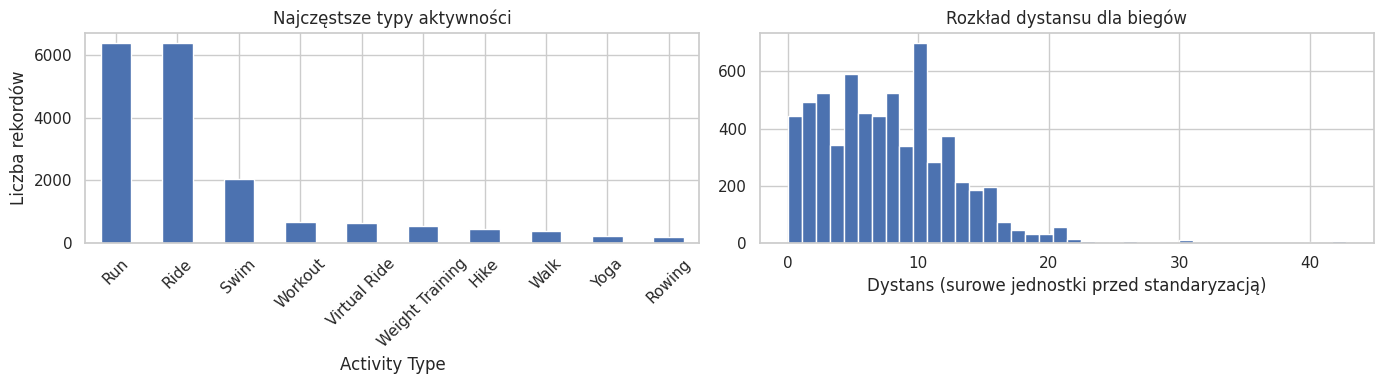

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

raw_df["Activity Type"].value_counts().head(10).plot(kind="bar", ax=axes[0], title="Najczęstsze typy aktywności")
axes[0].set_ylabel("Liczba rekordów")
axes[0].tick_params(axis="x", rotation=45)

run_mask = raw_df["Activity Type"].eq("Run")
raw_df.loc[run_mask, "Distance"].dropna().hist(bins=40, ax=axes[1])
axes[1].set_title("Rozkład dystansu dla biegów")
axes[1].set_xlabel("Dystans (surowe jednostki przed standaryzacją)")

plt.tight_layout()

## 4. Czyszczenie i standaryzacja danych

W tej sekcji:
- łączymy dane z obu źródeł,
- sprowadzamy dystans do metrów,
- usuwamy oczywiste anomalie,
- walidujemy tętno,
- uzupełniamy braki.

To jest moment, w którym warto podkreślić, że decyzje o filtracji danych są częścią modelowania, a nie tylko sprzątaniem.

In [20]:
def standardize_and_clean(strava_df: pd.DataFrame, garmin_df: pd.DataFrame) -> pd.DataFrame:
    df = pd.concat([strava_df, garmin_df], ignore_index=True, sort=False)

    df["Distance"] = pd.to_numeric(df["Distance"], errors="coerce")
    df.loc[df["source"] == "strava", "Distance"] = df.loc[df["source"] == "strava", "Distance"] * 1000
    df.loc[df["source"] == "garmin", "Distance"] = df.loc[df["source"] == "garmin", "Distance"] * 1000

    numeric_cols = [
        "Elapsed Time", "Moving Time", "Distance", "Max Heart Rate", "Average Heart Rate",
        "Max Speed", "Average Speed", "Elevation Gain", "Elevation Loss", "Average Temperature"
    ]
    for col in numeric_cols:
        if col not in df.columns:
            df[col] = np.nan
        df[col] = pd.to_numeric(df[col], errors="coerce")

    unrealistic_run = (
        df["Activity Type"].eq("Run")
        & (
            (df["Average Speed"] > 8.0)
            | (df["Max Speed"] > 15.0)
            | (df["Distance"] < 1000)
        )
    )
    print(f"Usuwam {unrealistic_run.sum()} biegów z nierealistycznymi parametrami.")
    df = df.loc[~unrealistic_run].copy()

    hr_mask = df["Average Heart Rate"].between(40, 220)
    print(f"Usuwam {(~hr_mask).sum()} aktywności bez poprawnego Average Heart Rate.")
    df = df.loc[hr_mask].copy()

    has_any_hr = df.groupby("athlete")[["Average Heart Rate", "Max Heart Rate"]].apply(lambda x: x.notna().any().any())
    athletes_to_keep = has_any_hr[has_any_hr].index
    df = df[df["athlete"].isin(athletes_to_keep)].copy()

    numeric_cols = df.select_dtypes(include="number").columns.tolist()
    activity_medians = df.groupby("Activity Type")[numeric_cols].median().to_dict(orient="index")

    def fill_group(group):
        activity_type = group.name[1]
        filled = group.fillna(group.median(numeric_only=True))
        for col in numeric_cols:
            if filled[col].isna().any():
                fallback = activity_medians.get(activity_type, {}).get(col, np.nan)
                filled[col] = filled[col].fillna(fallback)
        return filled

    df[numeric_cols] = (
        df.groupby(["athlete", "Activity Type"], group_keys=False)[numeric_cols]
        .apply(fill_group)
    )

    df = df.dropna(subset=["Activity Date", "Activity Type", "Distance"])
    df = df.sort_values(["athlete", "Activity Date"]).reset_index(drop=True)
    df["Activity ID"] = np.arange(1, len(df) + 1)
    return df


clean_df = standardize_and_clean(strava_df, garmin_df)
print(clean_df.shape)
clean_df.head()

Usuwam 429 biegów z nierealistycznymi parametrami.
Usuwam 7251 aktywności bez poprawnego Average Heart Rate.
(10539, 15)


,Activity ID,Activity Date,Activity Type,Elapsed Time,Distance,Max Heart Rate,Moving Time,Max Speed,Average Speed,Elevation Gain,Elevation Loss,Average Heart Rate,Average Temperature,athlete,source
0,1,2024-09-20 16:59:31,Ride,5300.0,24740.0,157.0,4966.0,8.138889,4.666667,77.0,74.0,126.0,21.0,garmin_01,garmin
1,2,2024-09-21 08:21:28,Ride,4266.0,20060.0,172.0,3756.0,8.277778,4.694444,73.0,70.0,134.0,18.0,garmin_01,garmin
2,3,2024-09-22 16:07:15,Ride,8115.0,23730.0,145.0,4504.0,8.916667,2.916667,82.0,77.0,106.0,23.0,garmin_01,garmin
3,4,2024-09-23 17:18:37,Ride,4571.0,20020.0,173.0,3833.0,8.166667,4.388889,81.0,69.0,127.0,22.5,garmin_01,garmin
4,5,2024-09-25 17:20:25,Ride,3855.0,20410.0,142.0,3662.0,7.750000,5.305556,69.0,66.0,115.0,22.5,garmin_01,garmin


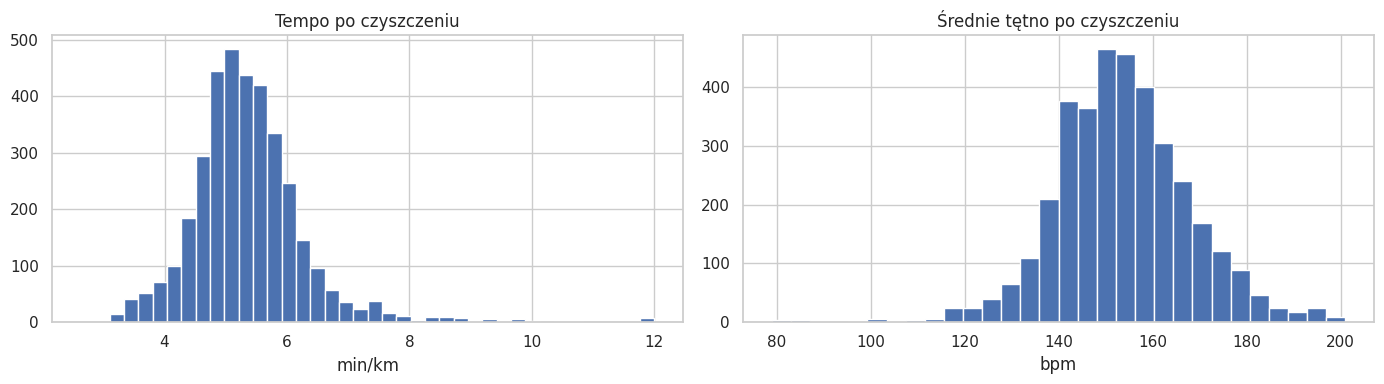

In [21]:
run_df = clean_df[clean_df["Activity Type"] == "Run"].copy()
run_df["pace_min_per_km"] = (run_df["Moving Time"] / 60) / (run_df["Distance"] / 1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
run_df["pace_min_per_km"].dropna().clip(upper=12).hist(bins=40, ax=axes[0])
axes[0].set_title("Tempo po czyszczeniu")
axes[0].set_xlabel("min/km")

run_df["Average Heart Rate"].dropna().hist(bins=30, ax=axes[1])
axes[1].set_title("Średnie tętno po czyszczeniu")
axes[1].set_xlabel("bpm")
plt.tight_layout()

## 5. Szukanie biegów startowych

W surowych danych zwykle nie ma etykiety `is_race`. Dlatego tworzymy heurystykę inspirowaną oryginalnym notebookiem:
- wysokie tętno względem HRmax,
- wyższa prędkość niż zwykle,
- popularny dystans startowy,
- sensowna relacja `Elapsed Time / Moving Time`.

To dobra okazja, żeby porozmawiać o tym, że etykiety w projektach data science często trzeba skonstruować samemu.

In [22]:
def estimate_hrmax(df: pd.DataFrame) -> dict:
    run_ride = df[df["Activity Type"].isin(["Run", "Ride"])].copy()
    top10 = (
        run_ride.sort_values(["athlete", "Max Heart Rate"], ascending=[True, False])
        .groupby("athlete")["Max Heart Rate"]
        .apply(lambda s: s.head(10).mean())
    )
    return top10.to_dict()


def identify_triathlon_runs(df: pd.DataFrame, max_time_gap_hours: int = 6) -> pd.DataFrame:
    df = df.copy()
    df["is_triathlon"] = 0

    for athlete, athlete_data in df.groupby("athlete"):
        athlete_data = athlete_data.sort_values("Activity Date")
        for i in range(len(athlete_data) - 1):
            current = athlete_data.iloc[i]
            nxt = athlete_data.iloc[i + 1]
            if current["Activity Type"] == "Ride" and nxt["Activity Type"] == "Run":
                gap_hours = (nxt["Activity Date"] - current["Activity Date"]).total_seconds() / 3600
                if gap_hours <= max_time_gap_hours:
                    df.loc[nxt.name, "is_triathlon"] = 1
    return df


def identify_races(df: pd.DataFrame, hr_threshold: float = 0.86, days_window: int = 365) -> pd.DataFrame:
    df = df.copy()
    common_race_distances = [5000, 10000, 21100, 42195]
    run_mask = df["Activity Type"].eq("Run")
    run_df = df.loc[run_mask].sort_values(["athlete", "Activity Date"]).copy()

    rolling_parts = []
    for athlete, subdf in run_df.groupby("athlete"):
        subdf = subdf.sort_values("Activity Date").set_index("Activity Date")
        subdf["avg_distance_runner"] = subdf["Distance"].rolling(f"{days_window}D", min_periods=1).mean()
        subdf["avg_speed_runner"] = subdf["Average Speed"].rolling(f"{days_window}D", min_periods=1).mean()
        rolling_parts.append(subdf.reset_index())

    rolling_df = pd.concat(rolling_parts, ignore_index=True)
    df = df.merge(
        rolling_df[["Activity ID", "avg_distance_runner", "avg_speed_runner"]],
        on="Activity ID",
        how="left",
    )

    cond_hr = df["Average Heart Rate"] > (df["HRMax"] * hr_threshold)
    cond_distance = df["Distance"] > 40000
    cond_speed = df["Average Speed"] > 1.4 * df["avg_speed_runner"]
    df["time_ratio"] = df["Elapsed Time"] / df["Moving Time"].replace(0, np.nan)
    cond_ratio = df["time_ratio"] <= 1.10
    cond_min_distance = df["Distance"] >= 3000

    is_common_distance = pd.Series(False, index=df.index)
    for race_dist in common_race_distances:
        lower = race_dist * 0.90
        upper = race_dist * 1.10
        is_common_distance |= df["Distance"].between(lower, upper)

    df["race_score"] = (
        2 * cond_hr.astype(int)
        + 2 * cond_distance.astype(int)
        + 2 * cond_speed.astype(int)
        + df["is_triathlon"].astype(int)
        + is_common_distance.astype(int)
    )

    df["is_race"] = run_mask & cond_min_distance & cond_ratio & (df["race_score"] >= 2)
    return df


hrmax_map = estimate_hrmax(clean_df)
clean_df["HRMax"] = clean_df["athlete"].map(hrmax_map)
clean_df = identify_triathlon_runs(clean_df)
model_df = identify_races(clean_df)

print("Liczba wykrytych biegów startowych:", int(model_df["is_race"].sum()))
model_df.loc[model_df["is_race"], ["athlete", "Activity Date", "Distance", "Average Speed", "Average Heart Rate"]].head(10)

Liczba wykrytych biegów startowych: 305


,athlete,Activity Date,Distance,Average Speed,Average Heart Rate
18,garmin_01,2024-11-24 08:40:35,4830.0,2.570694,161.0
33,garmin_01,2025-03-01 08:35:18,10200.0,2.512563,160.0
47,garmin_01,2025-04-07 19:36:23,10010.0,2.570694,161.0
49,garmin_01,2025-04-10 18:45:30,10000.0,2.666667,164.0
138,garmin_02,2024-12-21 08:34:05,10250.0,2.577320,159.0
257,garmin_02,2025-03-01 08:35:18,10200.0,2.512563,160.0
316,garmin_02,2025-04-07 19:36:23,10010.0,2.570694,161.0
320,garmin_02,2025-04-10 18:45:30,10000.0,2.666667,164.0
340,garmin_02,2025-04-26 08:08:46,10100.0,2.923977,130.0
362,garmin_02,2025-05-11 16:00:53,4910.0,3.095975,135.0


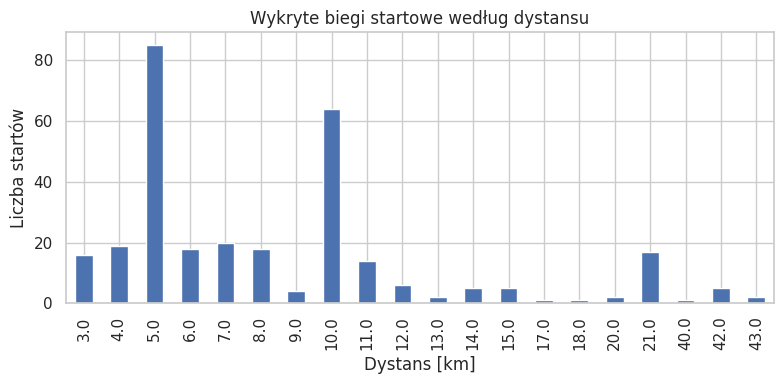

In [23]:
race_only = model_df[model_df["is_race"]].copy()
race_only["race_distance_km"] = race_only["Distance"] / 1000

plt.figure(figsize=(8, 4))
race_only["race_distance_km"].round().value_counts().sort_index().plot(kind="bar")
plt.title("Wykryte biegi startowe według dystansu")
plt.xlabel("Dystans [km]")
plt.ylabel("Liczba startów")
plt.tight_layout()

## 6. Cechy do modelu bazowego

Zamiast od razu budować model sekwencyjny, zaczniemy od prostszej wersji: dla każdego startu zbudujemy agregaty z ostatnich 90 dni treningu.

**Co z historii treningowej może mówić coś o przyszłym wyniku?**

In [24]:
def create_tabular_race_dataset(df: pd.DataFrame, lookback_days: int = 90, min_runs: int = 3) -> pd.DataFrame:
    rows = []
    df = df.sort_values(["athlete", "Activity Date"]).copy()

    for athlete, athlete_df in df.groupby("athlete"):
        athlete_df = athlete_df.sort_values("Activity Date").reset_index(drop=True)
        split_idx = max(1, int(len(athlete_df) * 0.8))
        test_start_date = athlete_df.iloc[split_idx]["Activity Date"] if split_idx < len(athlete_df) else pd.Timestamp.max
        athlete_runs = athlete_df[athlete_df["Activity Type"] == "Run"]
        athlete_races = athlete_runs[athlete_runs["is_race"]]

        for _, race in athlete_races.iterrows():
            race_date = race["Activity Date"]
            window = athlete_df[
                (athlete_df["Activity Date"] < race_date)
                & (athlete_df["Activity Date"] >= race_date - pd.Timedelta(days=lookback_days))
            ].copy()

            # Okno wejściowe może zawierać także wcześniejsze starty, byle tylko sprzed analizowanego biegu.
            run_window = athlete_runs[
                (athlete_runs["Activity Date"] < race_date)
                & (athlete_runs["Activity Date"] >= race_date - pd.Timedelta(days=lookback_days))
            ].copy()
            if len(run_window) < min_runs:
                continue

            split = "test" if race_date >= test_start_date else "train"

            row = {
                "athlete": athlete,
                "race_date": race_date,
                "split": split,
                "race_distance_m": race["Distance"],
                "race_distance_km": race["Distance"] / 1000,
                "race_elevation_gain_m": race["Elevation Gain"],
                "days_window": lookback_days,
                "runs_count": len(run_window),
                "run_km_total": run_window["Distance"].sum() / 1000,
                "run_time_h_total": run_window["Elapsed Time"].sum() / 3600,
                "bike_sessions": int((window["Activity Type"] == "Ride").sum()),
                "swim_sessions": int((window["Activity Type"] == "Swim").sum()),
                "strength_sessions": int((window["Activity Type"] == "Weight Training").sum()),
                "target_pace_sec_per_km": race["Moving Time"] / (race["Distance"] / 1000),
            }
            rows.append(row)

    return pd.DataFrame(rows)


race_features = create_tabular_race_dataset(model_df, lookback_days=90)
print(race_features.shape)
race_features.head()


(293, 14)


,athlete,race_date,split,race_distance_m,race_distance_km,race_elevation_gain_m,days_window,runs_count,run_km_total,run_time_h_total,bike_sessions,swim_sessions,strength_sessions,target_pace_sec_per_km
0,garmin_01,2024-11-24 08:40:35,train,4830.0,4.83,19.0,90,8,53.49,5.747778,10,0,0,388.405797
1,garmin_01,2025-03-01 08:35:18,train,10200.0,10.20,55.0,90,11,110.19,11.667500,0,0,0,397.352941
2,garmin_01,2025-04-07 19:36:23,train,10010.0,10.01,56.0,90,10,101.71,10.884167,9,0,0,388.411588
3,garmin_01,2025-04-10 18:45:30,train,10000.0,10.00,69.0,90,11,111.72,11.966111,10,0,0,374.300000
4,garmin_02,2024-12-21 08:34:05,train,10250.0,10.25,58.0,90,9,24.02,2.451667,0,0,1,387.024390


In [25]:
def sec_per_km_to_minsec(value):
    total_seconds = int(round(value))
    minutes = total_seconds // 60
    seconds = total_seconds % 60
    return f"{minutes}:{seconds:02d} min/km"


race_features.describe(include="all").T.head(20)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
athlete,293,17,strava_15,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race_date,293,NaN,NaN,NaN,2024-05-22 07:11:17.221843200,2020-08-05 16:12:29,2023-08-20 08:58:44,2024-10-20 08:06:54,2025-06-15 08:21:10,2025-10-19 08:00:11,NaN
split,293,2,train,222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race_distance_m,293.0,NaN,NaN,NaN,9244.163823,3000.0,5020.0,7240.0,10140.0,42790.0,7119.843561
race_distance_km,293.0,NaN,NaN,NaN,9.244164,3.0,5.02,7.24,10.14,42.79,7.119844
race_elevation_gain_m,293.0,NaN,NaN,NaN,54.482253,0.0,9.8,25.4,57.0,1394.0,113.540861
days_window,293.0,NaN,NaN,NaN,90.0,90.0,90.0,90.0,90.0,90.0,0.0
runs_count,293.0,NaN,NaN,NaN,27.665529,3.0,11.0,24.0,39.0,96.0,19.687735
run_km_total,293.0,NaN,NaN,NaN,219.886177,15.5,93.04,187.8,285.13,787.99,165.984801
run_time_h_total,293.0,NaN,NaN,NaN,23.354428,1.473333,10.456111,20.21,31.4825,171.723889,19.946728


## 7. Model bazowy: Linear Regression

Ten model traktujemy jako szybki punkt odniesienia przed przejściem do głównego modelu warsztatów, czyli GRU.

Dlaczego warto go pokazać?
- daje szybki baseline,
- pozwala później sensownie porównać wyniki z GRU.


In [26]:
def athlete_time_split(df: pd.DataFrame):
    train_df = df[df["split"] == "train"].copy()
    test_df = df[df["split"] == "test"].copy()
    return train_df, test_df


def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape}


train_df, test_df = athlete_time_split(race_features)
feature_cols = [
    "race_distance_km", "race_elevation_gain_m",
    "runs_count", "run_km_total", "run_time_h_total",
    "bike_sessions", "swim_sessions", "strength_sessions",
]

target_col = "target_pace_sec_per_km"

X_train = train_df[feature_cols].fillna(0)
X_test = test_df[feature_cols].fillna(0)
y_train = train_df[target_col].values
y_test = test_df[target_col].values

baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)

metrics = evaluate_regression(y_test, y_pred)
for name, value in metrics.items():
    if name == "MAPE":
        print(f"{name}: {value:.2f}%")
    else:
        print(f"{name}: {value:.2f} sek/km")

MAE: 40.21 sek/km
RMSE: 49.34 sek/km
MAPE: 13.61%


In [27]:
results = test_df[["athlete", "race_date", "race_distance_km"]].copy()
results["tempo_rzeczywiste"] = y_test
results["tempo_pred"] = y_pred
results["blad_sek_na_km"] = y_pred - y_test
results["tempo_rzeczywiste_fmt"] = results["tempo_rzeczywiste"].apply(sec_per_km_to_minsec)
results["tempo_pred_fmt"] = results["tempo_pred"].apply(sec_per_km_to_minsec)

results.head(10)

,athlete,race_date,race_distance_km,tempo_rzeczywiste,tempo_pred,blad_sek_na_km,tempo_rzeczywiste_fmt,tempo_pred_fmt
29,strava_01,2025-07-28 21:07:25,8.50,327.294118,309.805784,-17.488334,5:27 min/km,5:10 min/km
30,strava_01,2025-09-28 07:00:53,42.39,262.915782,339.744264,76.828482,4:23 min/km,5:40 min/km
71,strava_07,2025-07-10 16:12:34,10.01,282.617383,327.449210,44.831827,4:43 min/km,5:27 min/km
72,strava_07,2025-07-23 18:04:34,10.01,289.110889,327.155262,38.044373,4:49 min/km,5:27 min/km
73,strava_07,2025-07-25 19:07:56,10.00,288.700000,319.515363,30.815363,4:49 min/km,5:20 min/km
74,strava_07,2025-07-29 16:14:57,10.01,277.622378,320.973102,43.350725,4:38 min/km,5:21 min/km
75,strava_07,2025-08-20 16:39:30,5.11,258.512720,301.373214,42.860494,4:19 min/km,5:01 min/km
76,strava_07,2025-08-24 16:35:10,10.01,266.733267,308.263966,41.530699,4:27 min/km,5:08 min/km
77,strava_07,2025-09-15 15:37:05,10.00,269.400000,310.945984,41.545984,4:29 min/km,5:11 min/km
78,strava_07,2025-10-08 15:05:56,10.01,279.820180,296.236456,16.416277,4:40 min/km,4:56 min/km


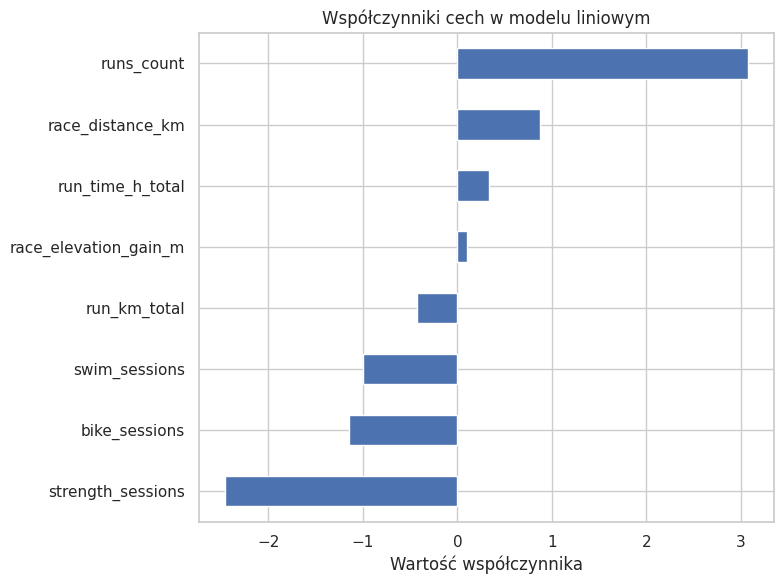

In [28]:
importance = pd.Series(baseline_model.coef_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importance.plot(kind="barh")
plt.title("Współczynniki cech w modelu liniowym")
plt.xlabel("Wartość współczynnika")
plt.tight_layout()

## 8. Model sekwencyjny GRU

To jest główny model warsztatów i najważniejsza część całego notebooka.

Różnica względem modelu bazowego jest taka, że:
- nie podajemy modelowi tylko agregatów,
- pokazujemy mu całą sekwencję treningów prowadzących do startu,
- osobno przekazujemy cechy statyczne.


In [29]:
def build_sequences_and_statics_split(df, days_window=360, test_split=0.2, min_runs=3):
    df = df.sort_values(["athlete", "Activity Date"]).reset_index(drop=True).copy()

    numeric_cols = [
        "Distance", "Elapsed Time", "Moving Time", "Average Speed", "Max Speed",
        "Average Heart Rate", "Max Heart Rate", "Elevation Gain", "Elevation Loss",
        "Average Temperature", "is_triathlon"
    ]
    df[numeric_cols] = df[numeric_cols].astype(np.float32)

    seqs, statics, ys, metas, splits = [], [], [], [], []

    for athlete, sub in df.groupby("athlete"):
        sub = sub.sort_values("Activity Date").reset_index(drop=True)
        split_idx = max(1, int(len(sub) * (1 - test_split)))
        test_start_date = sub.iloc[split_idx]["Activity Date"] if split_idx < len(sub) else pd.Timestamp.max
        runs = sub[sub["Activity Type"].str.lower() == "run"].copy()
        races = runs[runs["is_race"]].sort_values("Activity Date").copy()
        if races.empty:
            continue

        train_races = races[races["Activity Date"] < test_start_date]
        test_races = races[races["Activity Date"] >= test_start_date]

        for race_row, split in [*[(r, "train") for _, r in train_races.iterrows()], *[(r, "test") for _, r in test_races.iterrows()]]:
            race_date = race_row["Activity Date"]
            # Sekwencja wejściowa może zawierać także wcześniejsze starty, jeśli są przed analizowanym biegiem.
            window_runs = runs[
                (runs["Activity Date"] >= race_date - pd.Timedelta(days=days_window))
                & (runs["Activity Date"] < race_date)
            ].copy()
            if len(window_runs) < min_runs:
                continue

            window_runs["days_to_race"] = (race_date - window_runs["Activity Date"]).dt.days
            seq_features = [
                "days_to_race", "Distance", "Elapsed Time", "Moving Time", "Average Speed",
                "Max Speed", "Average Heart Rate", "Max Heart Rate",
                "Elevation Gain", "Elevation Loss", "Average Temperature"
            ]
            seq_array = window_runs[seq_features].to_numpy(dtype=np.float32)

            other_window = sub[
                (sub["Activity Type"].str.lower() != "run")
                & (sub["Activity Date"] >= race_date - pd.Timedelta(days=days_window))
                & (sub["Activity Date"] < race_date)
            ]

            def aggregate_activity(frame, names):
                mask = frame["Activity Type"].str.lower().isin(names)
                return (
                    float(frame.loc[mask, "Elapsed Time"].sum() or 0.0),
                    float(frame.loc[mask, "Distance"].sum() or 0.0),
                    int(mask.sum()),
                )

            swim_t, swim_dist, swim_sessions = aggregate_activity(other_window, ["swim"])
            bike_t, bike_dist, bike_sessions = aggregate_activity(other_window, ["ride"])
            gym_t, _, gym_sessions = aggregate_activity(other_window, ["weight training"])

            years_of_exp = (
                (runs["Activity Date"].max() - runs["Activity Date"].min()).days / 365.0
                if len(runs) > 1 else 0.0
            )

            run_km_total = float(window_runs["Distance"].sum() / 1000.0)
            run_time_h_total = float(window_runs["Elapsed Time"].sum() / 3600.0)
            run_km_mean = float(window_runs["Distance"].mean() / 1000.0)
            run_pace_mean = float((window_runs["Moving Time"].sum() / 60.0) / (window_runs["Distance"].sum() / 1000.0))
            run_pace_std = float(((window_runs["Moving Time"] / 60.0) / (window_runs["Distance"] / 1000.0)).std() or 0.0)
            longest_run_km = float(window_runs["Distance"].max() / 1000.0)
            days_since_last_run = float((race_date - window_runs["Activity Date"].max()).days)

            statics.append({
                "years_of_experience": years_of_exp,
                "run_km_total": run_km_total,
                "run_time_h_total": run_time_h_total,
                "run_km_mean": run_km_mean,
                "run_pace_mean": run_pace_mean,
                "run_pace_std": run_pace_std,
                "longest_run_km": longest_run_km,
                "days_since_last_run": days_since_last_run,
                "swim_t_total": swim_t,
                "swim_dist_total": swim_dist,
                "swim_sessions": swim_sessions,
                "bike_t_total": bike_t,
                "bike_dist_total": bike_dist,
                "bike_sessions": bike_sessions,
                "gym_t_total": gym_t,
                "gym_sessions": gym_sessions,
                "race_distance_m": float(race_row["Distance"]),
                "race_elevation_gain_m": float(race_row["Elevation Gain"]),
                "is_triathlon": float(race_row["is_triathlon"]),
            })

            y_val = race_row.get("Moving Time", race_row.get("Elapsed Time", np.nan))
            pace_sec_per_km = float(y_val) / (float(race_row["Distance"]) / 1000.0)

            seqs.append(seq_array)
            ys.append(pace_sec_per_km)
            metas.append({
                "athlete": athlete,
                "race_date": race_date,
                "race_distance_m": float(race_row["Distance"]),
                "split": split,
            })
            splits.append(split)

    statics_df = pd.DataFrame(statics)
    meta_df = pd.DataFrame(metas)
    y = np.array(ys, dtype=np.float32)

    train_idx = [i for i, split in enumerate(splits) if split == "train"]
    test_idx = [i for i, split in enumerate(splits) if split == "test"]

    train_seqs = [seqs[i] for i in train_idx]
    test_seqs = [seqs[i] for i in test_idx]
    train_stat_df = statics_df.iloc[train_idx].reset_index(drop=True)
    test_stat_df = statics_df.iloc[test_idx].reset_index(drop=True)
    train_y = y[train_idx]
    test_y = y[test_idx]
    train_meta = meta_df.iloc[train_idx].reset_index(drop=True)
    test_meta = meta_df.iloc[test_idx].reset_index(drop=True)

    return (train_seqs, train_stat_df, train_y, train_meta), (test_seqs, test_stat_df, test_y, test_meta)


def scale_and_pad(train_seqs, test_seqs, train_stat_df, test_stat_df, train_y, test_y,
                  static_numeric_cols, static_binary_cols, seq_numeric_dim, pad_value=999.0):
    static_scaler = StandardScaler()
    X_static_train_numeric = static_scaler.fit_transform(train_stat_df[static_numeric_cols].values)
    X_static_test_numeric = static_scaler.transform(test_stat_df[static_numeric_cols].values)

    X_static_train_binary = train_stat_df[static_binary_cols].values.astype(float)
    X_static_test_binary = test_stat_df[static_binary_cols].values.astype(float)

    X_static_train = np.column_stack([X_static_train_numeric, X_static_train_binary])
    X_static_test = np.column_stack([X_static_test_numeric, X_static_test_binary])

    seq_scaler = StandardScaler()
    seq_scaler.fit(np.vstack([seq for seq in train_seqs if len(seq) > 0]))

    train_scaled = [seq_scaler.transform(seq) if len(seq) > 0 else np.empty((0, seq_numeric_dim)) for seq in train_seqs]
    test_scaled = [seq_scaler.transform(seq) if len(seq) > 0 else np.empty((0, seq_numeric_dim)) for seq in test_seqs]

    max_len = max(max(len(seq) for seq in train_scaled), max(len(seq) for seq in test_scaled))
    X_seq_train = pad_sequences(train_scaled, maxlen=max_len, padding="post", value=pad_value)
    X_seq_test = pad_sequences(test_scaled, maxlen=max_len, padding="post", value=pad_value)

    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(train_y.reshape(-1, 1)).flatten()
    y_test_scaled = y_scaler.transform(test_y.reshape(-1, 1)).flatten()

    return X_seq_train, X_seq_test, X_static_train, X_static_test, y_train_scaled, y_test_scaled, {
        "seq": seq_scaler,
        "static": static_scaler,
        "y": y_scaler,
    }


def build_gru_race_model(seq_shape, static_shape, hidden_size=16, dense_units=32, dropout_rate=0.3):
    """
    seq_shape: (max_seq_len, n_seq_features)
    static_shape: (n_static_features,)
    """
    # Sequential branch
    seq_input = Input(shape=seq_shape, name="seq_input")
    x = Masking(mask_value=999.0)(seq_input)
    x = Bidirectional(GRU(hidden_size, return_sequences=True, kernel_regularizer="l2", name="gru_1"))(x)
    x = Dropout(dropout_rate)(x)
    x = BatchNormalization()(x)
    x = Bidirectional(GRU(hidden_size, return_sequences=False, kernel_regularizer="l2", name="gru_2"))(x)
    x = Dense(dense_units, activation="relu", kernel_regularizer="l2")(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Static branch
    static_input = Input(shape=static_shape, name="static_input")
    s = Dense(dense_units, activation="relu", kernel_regularizer="l2")(static_input)
    s = BatchNormalization()(s)
    s = Dropout(dropout_rate)(s)

    # Merge branches
    merged = concatenate([x, s])
    merged = Dense(dense_units, activation="relu", kernel_regularizer="l2")(merged)
    merged = BatchNormalization()(merged)
    merged = Dropout(dropout_rate)(merged)

    #Output
    output = Dense(1, activation="linear", name="pace_sec_per_km")(merged)

    # Model
    model = Model(inputs=[seq_input, static_input], outputs=output)
    model.compile(
        optimizer=Adam(learning_rate=8e-4),
        loss="mae",
        metrics=["mae", "mse", "mape"]
    )

    return model

early_stop = EarlyStopping(monitor="val_loss", patience=50, restore_best_weights=True)
checkpoint = ModelCheckpoint("best_gru_model.keras", save_best_only=True, monitor="val_loss")


In [30]:
if TF_AVAILABLE:
    (train_seqs, train_stat_df, train_y, train_meta), (test_seqs, test_stat_df, test_y, test_meta) = build_sequences_and_statics_split(model_df)

    static_numeric_cols = [
        "years_of_experience",
        "run_km_total", "run_time_h_total", "run_km_mean", "run_pace_mean", "run_pace_std",
        "longest_run_km", "days_since_last_run",
        "swim_t_total", "swim_dist_total", "swim_sessions",
        "bike_t_total", "bike_dist_total", "bike_sessions",
        "gym_t_total", "gym_sessions",
        "race_distance_m", "race_elevation_gain_m",
    ]
    static_binary_cols = ["is_triathlon"]

    X_seq_train, X_seq_test, X_static_train, X_static_test, y_train_scaled, y_test_scaled, scalers = scale_and_pad(
        train_seqs,
        test_seqs,
        train_stat_df,
        test_stat_df,
        train_y,
        test_y,
        static_numeric_cols,
        static_binary_cols,
        seq_numeric_dim=11,
    )

    seq_shape = (X_seq_train.shape[1], X_seq_train.shape[2])
    static_shape = (X_static_train.shape[1],)

    model = build_gru_race_model(seq_shape, static_shape)

    history = model.fit(
        [X_seq_train, X_static_train],
        y_train_scaled,
        validation_split=0.2,
        epochs=500,
        batch_size=16,
        callbacks=[
            early_stop,
            checkpoint,
        ],
        shuffle=True,
        verbose=0,
    )

    y_pred_scaled = model.predict([X_seq_test, X_static_test], verbose=0)
    y_pred_gru = scalers["y"].inverse_transform(y_pred_scaled).flatten()
    gru_metrics = evaluate_regression(test_y, y_pred_gru)

    for name, value in gru_metrics.items():
        if name == "MAPE":
            print(f"GRU {name}: {value:.2f}%")
        else:
            print(f"GRU {name}: {value:.2f} sek/km")
else:
    print("TensorFlow nie jest dostępny w tym środowisku. Sekcję GRU można uruchomić np. w Google Colab lub po instalacji tensorflow.")


GRU MAE: 23.96 sek/km
GRU RMSE: 30.34 sek/km
GRU MAPE: 8.93%


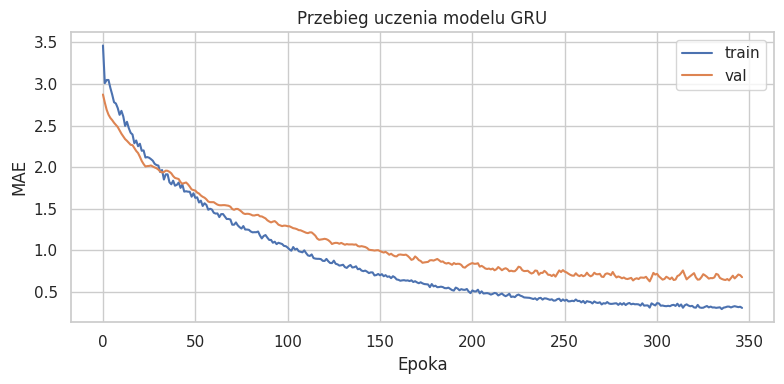

In [31]:
if TF_AVAILABLE:
    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="val")
    plt.title("Przebieg uczenia modelu GRU")
    plt.xlabel("Epoka")
    plt.ylabel("MAE")
    plt.legend()
    plt.tight_layout()

## 9. Pytania do dyskusji z uczestnikami

1. Jakie błędy może popełniać heurystyka wykrywania startów?
2. Czy 90 dni to dobre okno dla modelu bazowego?
3. Kiedy model sekwencyjny ma przewagę nad prostym modelem tabularnym?
4. Jakie dodatkowe dane mogłyby poprawić predykcję?
   - pogoda,
   - sen,
   - teren,
   - historia kontuzji,
   - strefy tętna.

## 10. Zadania dodatkowe

### Wersja podstawowa
- Policz medianę tempa dla każdego zawodnika i porównaj ją z tempem startowym.
- Zmień `lookback_days` z 90 na 30 lub 180 i porównaj wyniki.
- Dodaj nową cechę, np. liczbę długich biegów powyżej 20 km.

### Dalsze rozszerzenia
- Zmień model bazowy na `XGBoost` lub `RandomForest`.
- Zmień próg wykrywania startów i oceń, jak to wpływa na jakość danych.
- Rozbuduj model GRU o dodatkowe cechy sekwencyjne.